# California Housing Prices

**Análisis exploratorio y predicción del precio medio de viviendas en California.**

Este proyecto parte de la exploración del conjunto de datos `housing.csv` y avanza hacia la construcción de modelos de regresión. Se estudian las relaciones entre las características de las zonas y el precio medio de las viviendas, y se comparan tres algoritmos: regresión lineal, árbol de decisión y bosque aleatorio.

El objetivo es construir un flujo de trabajo claro y reproducible, manteniendo el enfoque del análisis original.

## 1. Exploración de los datos

Primero se revisa la estructura del conjunto de datos, los tipos de variables, los valores faltantes y la distribución de las categorías. Después se utilizan gráficos para identificar patrones generales.

In [ ]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Estilo general de las visualizaciones
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

data = pd.read_csv("Data")


print(f"Archivo cargado: {data.head()}")
print(f"Dimensiones del conjunto de datos: {data.shape[0]:,} filas y {data.shape[1]} columnas")

Archivo cargado:    longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  
Dimensiones del conjunto de datos: 20,640 filas y 10 colum

In [3]:
data.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


In [4]:
# Tipos de datos y cantidad de valores no nulos
data.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 10 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           20640 non-null  float64
 1   latitude            20640 non-null  float64
 2   housing_median_age  20640 non-null  float64
 3   total_rooms         20640 non-null  float64
 4   total_bedrooms      20433 non-null  float64
 5   population          20640 non-null  float64
 6   households          20640 non-null  float64
 7   median_income       20640 non-null  float64
 8   median_house_value  20640 non-null  float64
 9   ocean_proximity     20640 non-null  str    
dtypes: float64(9), str(1)
memory usage: 1.6 MB


In [5]:
# Resumen de valores faltantes por columna
missing_values = data.isna().sum().sort_values(ascending=False)
missing_values[missing_values > 0]

total_bedrooms    207
dtype: int64

In [6]:
# Distribución de las categorías de proximidad al océano
data["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     9136
INLAND        6551
NEAR OCEAN    2658
NEAR BAY      2290
ISLAND           5
Name: count, dtype: int64

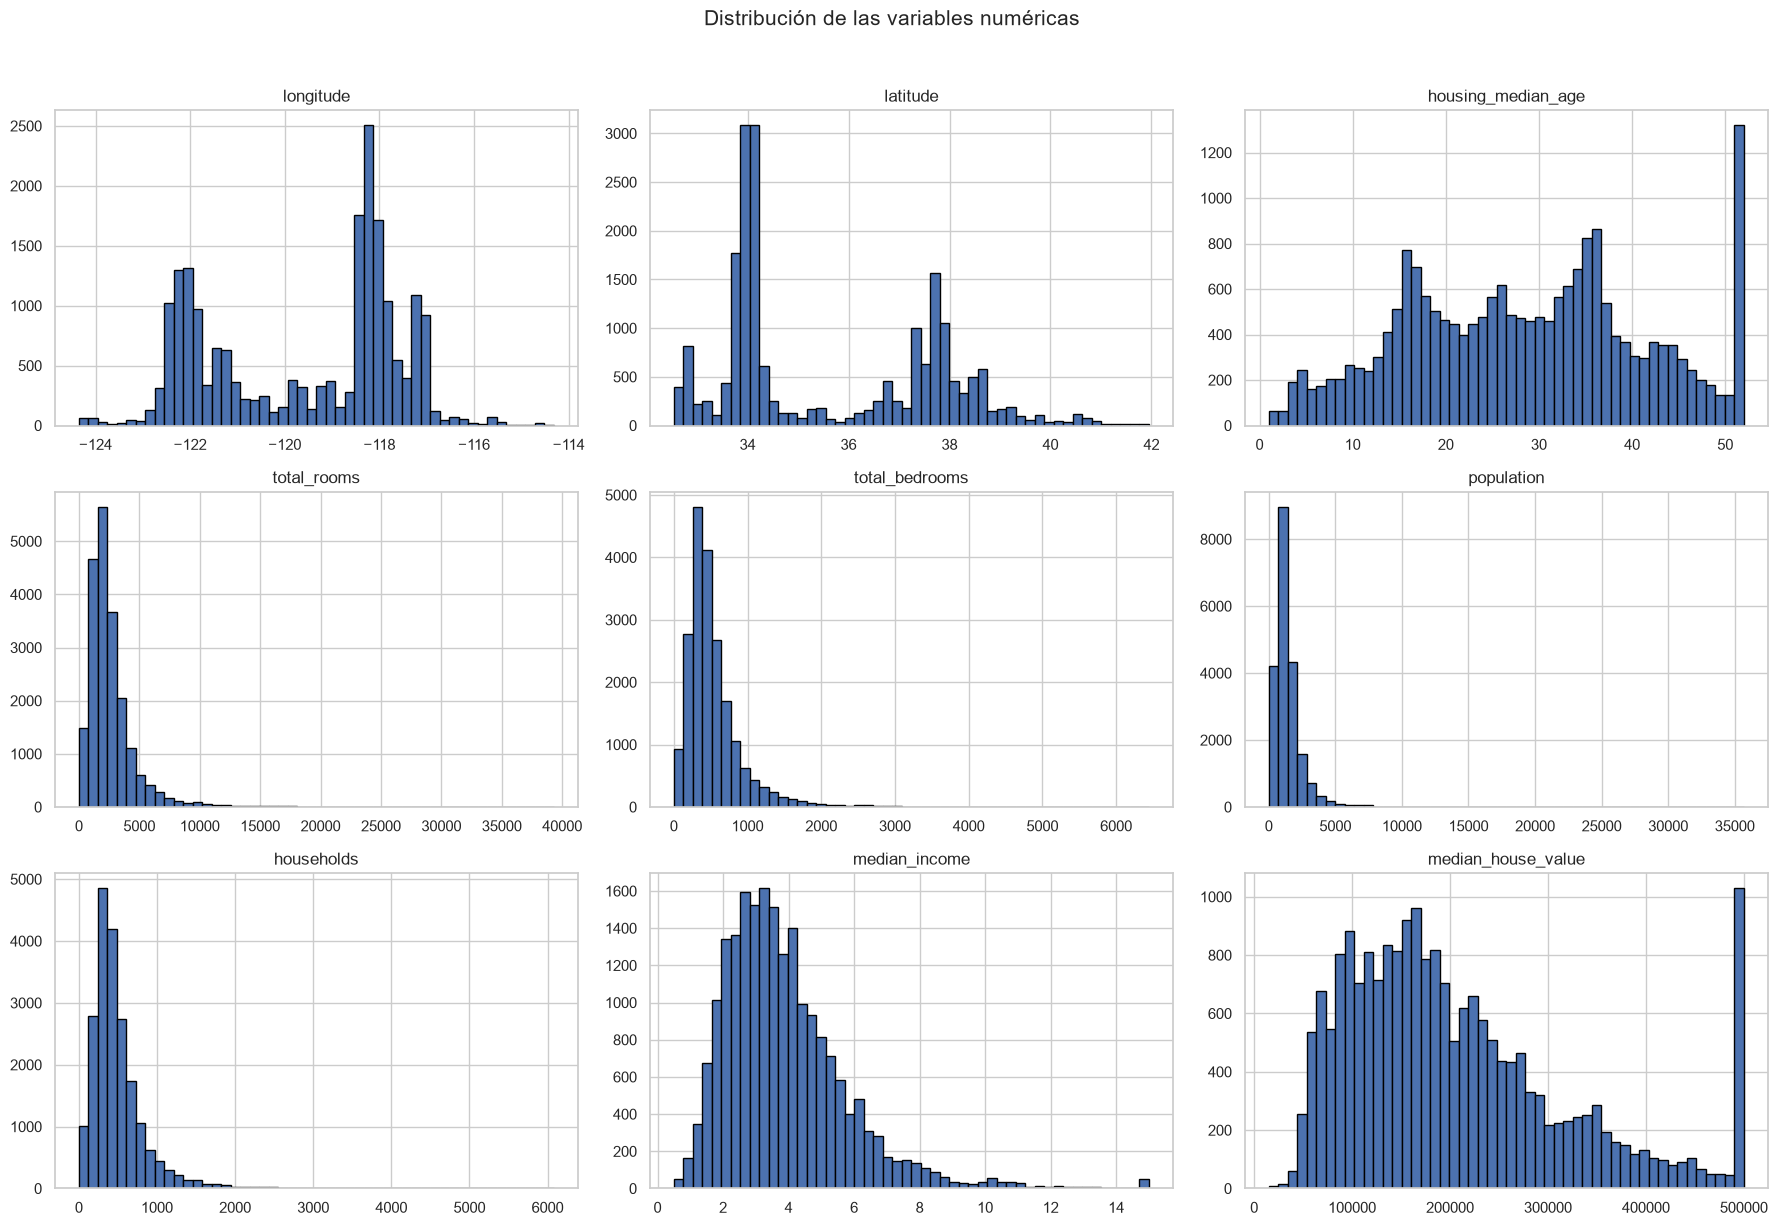

In [7]:
# Histogramas de las variables numéricas
data.hist(bins=50, figsize=(18, 12), edgecolor="black")
plt.suptitle("Distribución de las variables numéricas", y=1.02, fontsize=15)
plt.tight_layout()
plt.show()

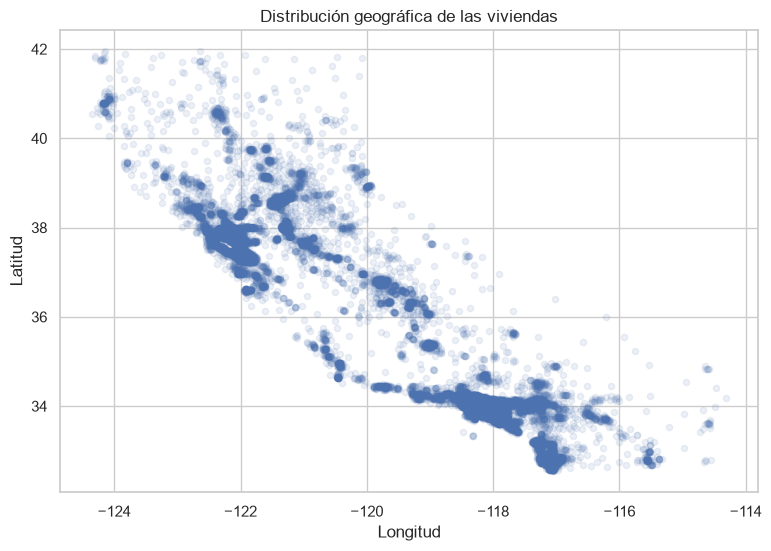

In [8]:
# Distribución geográfica de las observaciones
data.plot(kind="scatter", x="longitude", y="latitude", alpha=0.1, figsize=(9, 6))
plt.title("Distribución geográfica de las viviendas")
plt.xlabel("Longitud")
plt.ylabel("Latitud")
plt.show()

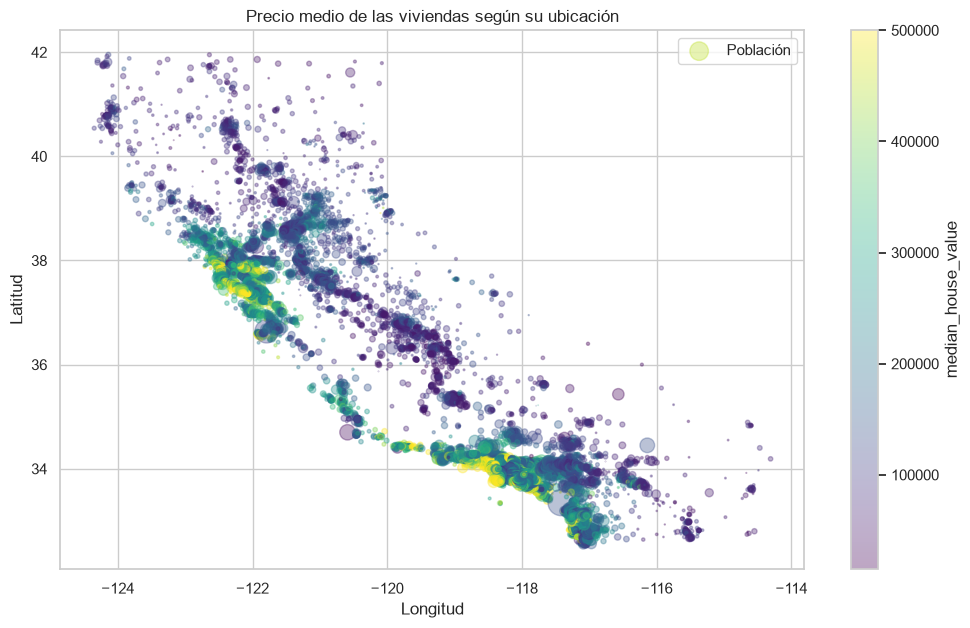

In [9]:
# Distribución geográfica: tamaño del punto = población; color = precio medio
ax = data.plot(
    kind="scatter",
    x="longitude",
    y="latitude",
    alpha=0.35,
    s=data["population"] / 100,
    label="Población",
    figsize=(12, 7),
    c="median_house_value",
    cmap="viridis",
    colorbar=True,
)
ax.set_title("Precio medio de las viviendas según su ubicación")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
plt.legend()
plt.show()

En el mapa se puede observar que la ubicación geográfica contiene información útil para el análisis. La distribución de los precios no es uniforme y presenta variaciones entre distintas zonas de California. Esto justifica evaluar las coordenadas como variables predictoras.

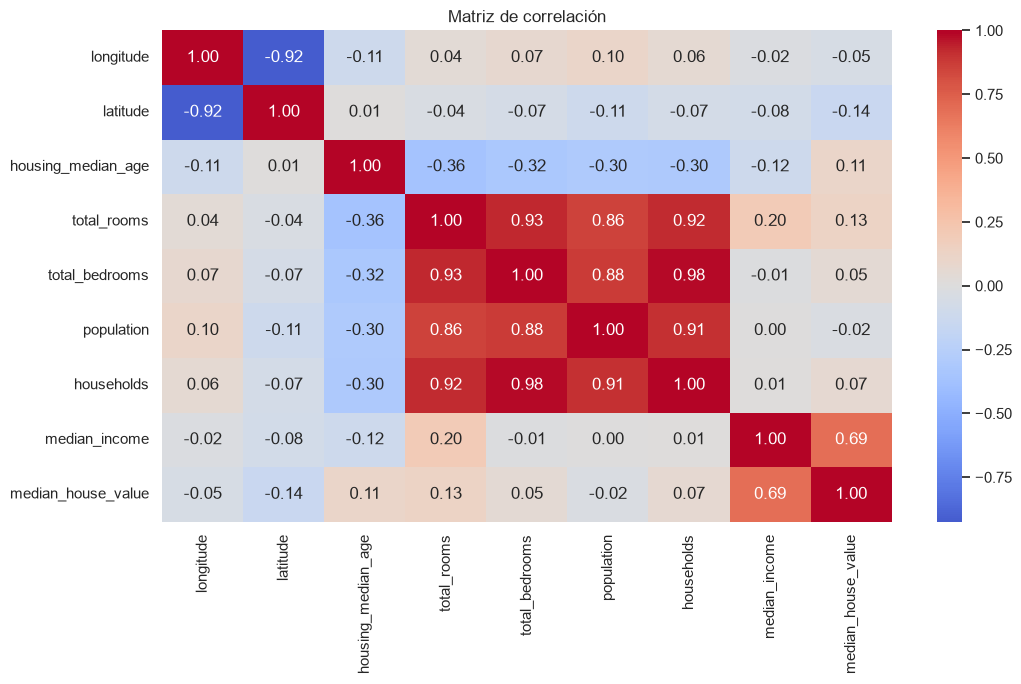

In [10]:
# Correlación entre variables numéricas
corr_matrix = data.corr(numeric_only=True)

plt.figure(figsize=(11, 7))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Matriz de correlación")
plt.tight_layout()
plt.show()

In [11]:
# Correlación de cada variable numérica con el precio medio
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value    1.000000
median_income         0.688075
total_rooms           0.134153
housing_median_age    0.105623
households            0.065843
total_bedrooms        0.049686
population           -0.024650
longitude            -0.045967
latitude             -0.144160
Name: median_house_value, dtype: float64

En esta primera revisión, `median_income` presenta una de las asociaciones lineales más altas con `median_house_value`. La correlación permite identificar relaciones, pero no demuestra causalidad ni permite descartar relaciones no lineales.

## 2. Combinación de atributos

Además de las variables originales, se crean tres características que expresan cantidades relativas por hogar o por habitación:

- **`rooms_per_household`:** número promedio de habitaciones por hogar.
- **`bedrooms_per_room`:** proporción de dormitorios respecto al total de habitaciones.
- **`population_per_household`:** población promedio por hogar.

Estas variables permiten representar mejor algunas características de las zonas que los conteos totales por sí solos.

In [12]:
# Evitar divisiones por cero en caso de encontrar hogares o habitaciones con valor cero

data["rooms_per_household"] = data["total_rooms"] / data["households"].replace(0, np.nan)
data["bedrooms_per_room"] = data["total_bedrooms"] / data["total_rooms"].replace(0, np.nan)
data["population_per_household"] = data["population"] / data["households"].replace(0, np.nan)

data[[
    "rooms_per_household",
    "bedrooms_per_room",
    "population_per_household",
]].describe()

,rooms_per_household,bedrooms_per_room,population_per_household
count,20640.000000,20433.000000,20640.000000
mean,5.429000,0.213039,3.070655
std,2.474173,0.057983,10.386050
min,0.846154,0.100000,0.692308
25%,4.440716,0.175427,2.429741
50%,5.229129,0.203162,2.818116
75%,6.052381,0.239821,3.282261
max,141.909091,1.000000,1243.333333


In [13]:
# Correlación de las variables numéricas, incluidas las nuevas características
corr_matrix = data.corr(numeric_only=True)
corr_matrix["median_house_value"].sort_values(ascending=False)

median_house_value          1.000000
median_income               0.688075
rooms_per_household         0.151948
total_rooms                 0.134153
housing_median_age          0.105623
households                  0.065843
total_bedrooms              0.049686
population_per_household   -0.023737
population                 -0.024650
longitude                  -0.045967
latitude                   -0.144160
bedrooms_per_room          -0.255880
Name: median_house_value, dtype: float64

La creación de estas variables ayuda a describir la composición de los hogares. En particular, `bedrooms_per_room` puede aportar información distinta al número total de habitaciones. Su utilidad definitiva se debe valorar mediante el desempeño de los modelos, no solamente a partir de la correlación.

## 3. Preparación de los datos

La variable que se desea predecir es `median_house_value`. El resto de las columnas se utilizan como variables predictoras.

Se divide el conjunto de datos en entrenamiento (80 %) y prueba (20 %). La imputación de valores faltantes, el escalado y la codificación de la variable categórica se realizan dentro de un `Pipeline`. De esta manera, esos pasos se ajustan únicamente con los datos de entrenamiento y se evita utilizar información del conjunto de prueba durante el preprocesamiento.

In [14]:
from sklearn.model_selection import train_test_split

# Comprobar que estén presentes las columnas necesarias
target = "median_house_value"
required_columns = {target, "ocean_proximity"}
missing_columns = required_columns.difference(data.columns)

if missing_columns:
    raise ValueError(f"Faltan columnas necesarias en el archivo: {sorted(missing_columns)}")

# Separar variables predictoras y variable objetivo
X = data.drop(columns=[target]).copy()
y = data[target].copy()

if y.isna().any():
    raise ValueError("La variable objetivo contiene valores faltantes; revísalos antes de entrenar.")

# División reproducible de entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
)

print(f"Datos de entrenamiento: {X_train.shape}")
print(f"Datos de prueba: {X_test.shape}")

Datos de entrenamiento: (16512, 12)
Datos de prueba: (4128, 12)


In [15]:
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# Identificar variables numéricas y categóricas
numeric_features = X.select_dtypes(include=np.number).columns.tolist()
categorical_features = X.select_dtypes(exclude=np.number).columns.tolist()

# Tratamiento de variables numéricas: completar faltantes y estandarizar
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
])

# Tratamiento de variables categóricas: completar faltantes y aplicar One-Hot Encoding
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore")),
])

# Aplicar cada transformación al tipo de variable correspondiente
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features),
])

print("Variables numéricas:", numeric_features)
print("Variables categóricas:", categorical_features)

Variables numéricas: ['longitude', 'latitude', 'housing_median_age', 'total_rooms', 'total_bedrooms', 'population', 'households', 'median_income', 'rooms_per_household', 'bedrooms_per_room', 'population_per_household']
Variables categóricas: ['ocean_proximity']


## 4. Entrenamiento y comparación de modelos

Se entrenan los tres algoritmos trabajados en el análisis original. También se incluye un modelo base que predice siempre la mediana del precio del conjunto de entrenamiento; sirve como referencia para comprobar si los modelos aportan una mejora real.

Todos los modelos utilizan la misma división de entrenamiento y prueba. La comparación se realiza mediante:

- **R²:** proporción de la variabilidad de los precios explicada por el modelo. Un valor mayor suele indicar mejor ajuste.
- **MAE:** error absoluto medio, expresado en las unidades del precio.
- **RMSE:** raíz del error cuadrático medio; penaliza más los errores grandes.

In [16]:
from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

models = {
    "Modelo base": DummyRegressor(strategy="median"),
    "Regresión lineal": LinearRegression(),
    "Árbol de decisión": DecisionTreeRegressor(random_state=42),
    "Bosque aleatorio": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        n_jobs=-1,
    ),
}

# Cada algoritmo recibe el mismo preprocesamiento dentro de su propio pipeline
model_pipelines = {
    name: Pipeline(steps=[
        ("preprocessor", clone(preprocessor)),
        ("model", estimator),
    ])
    for name, estimator in models.items()
}

In [17]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

results = []
trained_models = {}
predictions = {}

for name, pipeline in model_pipelines.items():
    pipeline.fit(X_train, y_train)
    y_pred = pipeline.predict(X_test)

    trained_models[name] = pipeline
    predictions[name] = y_pred

    results.append({
        "Modelo": name,
        "R²": r2_score(y_test, y_pred),
        "MAE": mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_test, y_pred)),
    })

results_df = pd.DataFrame(results).set_index("Modelo").sort_values("R²", ascending=False)
results_df

,R²,MAE,RMSE
Modelo,,,
Bosque aleatorio,0.813020,31766.872613,49499.515596
Regresión lineal,0.635339,49645.492445,69127.038299
Árbol de decisión,0.627556,43092.870882,69860.829326
Modelo base,-0.050209,87403.992248,117311.671050


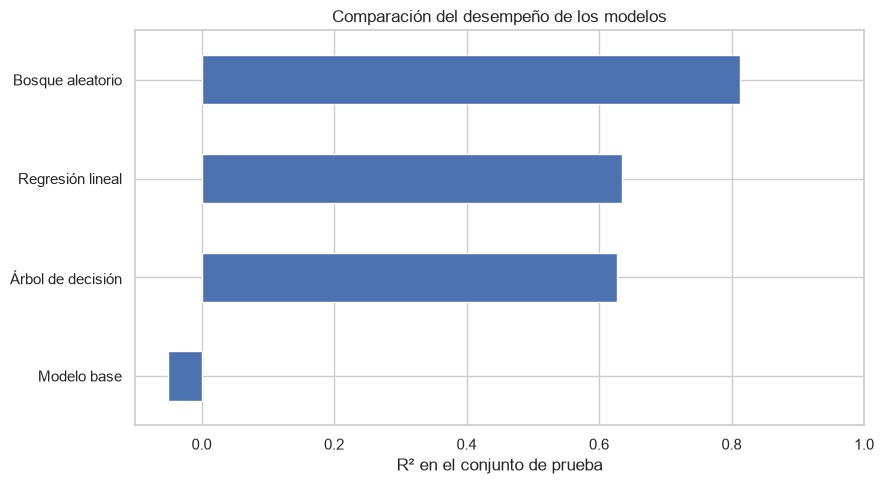

In [18]:
# Comparación visual de R²
ax = results_df["R²"].sort_values().plot(kind="barh", figsize=(9, 5))
ax.set_title("Comparación del desempeño de los modelos")
ax.set_xlabel("R² en el conjunto de prueba")
ax.set_ylabel("")
plt.xlim(min(0, results_df["R²"].min() - 0.05), 1)
plt.tight_layout()
plt.show()

## 5. Análisis de las predicciones

Se selecciona el modelo con el mayor R² en el conjunto de prueba y se comparan sus predicciones con los valores reales. Esta visualización ayuda a identificar si el modelo tiende a sobreestimar o subestimar determinados rangos de precios.

In [19]:
best_model_name = results_df.index[0]
best_model = trained_models[best_model_name]
best_predictions = predictions[best_model_name]

print(f"Mejor modelo según R²: {best_model_name}")
print(f"R²:   {r2_score(y_test, best_predictions):.3f}")
print(f"MAE:  {mean_absolute_error(y_test, best_predictions):,.2f}")
print(f"RMSE: {np.sqrt(mean_squared_error(y_test, best_predictions)):,.2f}")

Mejor modelo según R²: Bosque aleatorio
R²:   0.813
MAE:  31,766.87
RMSE: 49,499.52


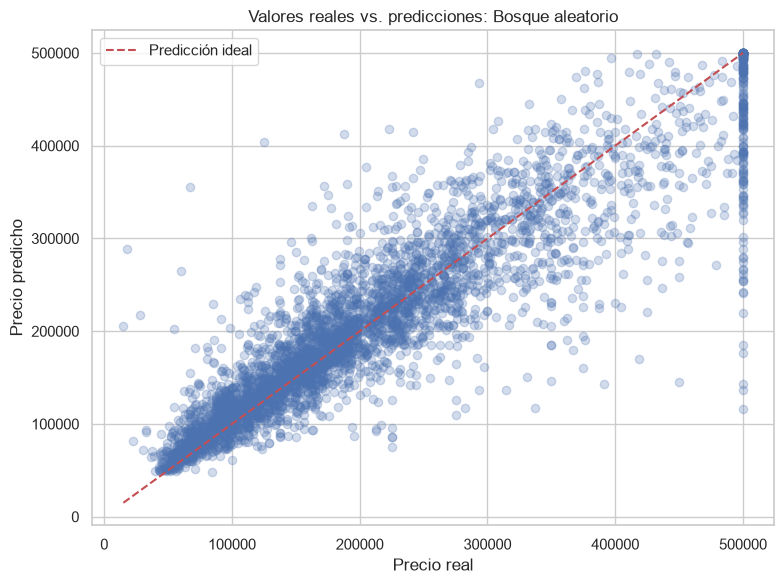

In [20]:
# Valores reales frente a valores predichos
plt.figure(figsize=(8, 6))
plt.scatter(y_test, best_predictions, alpha=0.25)

min_value = min(y_test.min(), best_predictions.min())
max_value = max(y_test.max(), best_predictions.max())
plt.plot([min_value, max_value], [min_value, max_value], "r--", label="Predicción ideal")

plt.title(f"Valores reales vs. predicciones: {best_model_name}")
plt.xlabel("Precio real")
plt.ylabel("Precio predicho")
plt.legend()
plt.tight_layout()
plt.show()

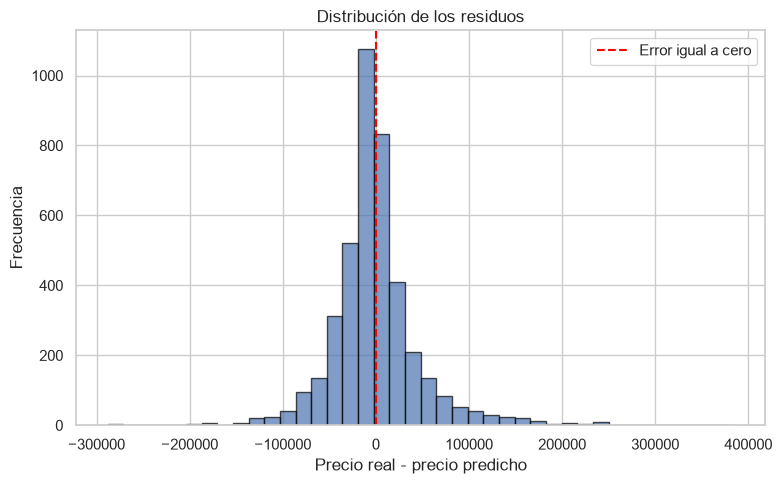

In [21]:
# Distribución de los errores (residuos)
residuals = y_test - best_predictions

plt.figure(figsize=(8, 5))
plt.hist(residuals, bins=40, edgecolor="black", alpha=0.7)
plt.axvline(0, color="red", linestyle="--", label="Error igual a cero")
plt.title("Distribución de los residuos")
plt.xlabel("Precio real - precio predicho")
plt.ylabel("Frecuencia")
plt.legend()
plt.tight_layout()
plt.show()

## 6. Importancia de las variables

Para complementar la comparación, se revisa la importancia de las variables del bosque aleatorio. Esta medida permite identificar cuáles fueron más utilizadas por el modelo para realizar sus predicciones. No debe interpretarse como una relación causal.

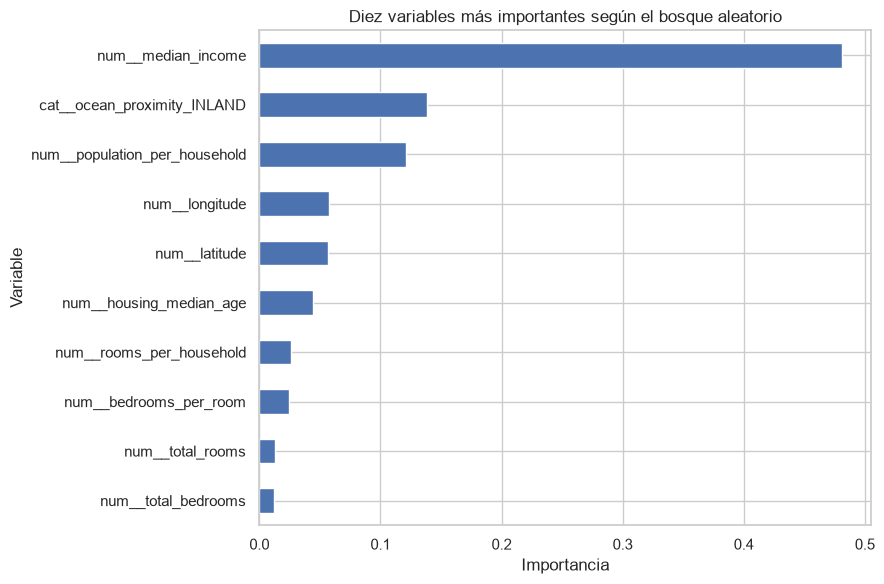

num__median_income               0.481185
cat__ocean_proximity_INLAND      0.138438
num__population_per_household    0.120916
num__longitude                   0.057680
num__latitude                    0.056493
num__housing_median_age          0.044269
num__rooms_per_household         0.025963
num__bedrooms_per_room           0.024478
num__total_rooms                 0.012750
num__total_bedrooms              0.011962
dtype: float64

In [22]:
forest_pipeline = trained_models["Bosque aleatorio"]
forest_model = forest_pipeline.named_steps["model"]
forest_preprocessor = forest_pipeline.named_steps["preprocessor"]

feature_names = forest_preprocessor.get_feature_names_out()
importances = pd.Series(
    forest_model.feature_importances_,
    index=feature_names,
).sort_values(ascending=False)

importances.head(10).sort_values().plot(kind="barh", figsize=(9, 6))
plt.title("Diez variables más importantes según el bosque aleatorio")
plt.xlabel("Importancia")
plt.ylabel("Variable")
plt.tight_layout()
plt.show()

importances.head(10)

## 7. Conclusiones

Las conclusiones se deben leer junto con la tabla de métricas obtenida al ejecutar el notebook. En particular:

1. **Relación entre variables:** en la exploración inicial, el ingreso medio (`median_income`) mostró una asociación positiva destacada con el precio medio de las viviendas. Algunas variables derivadas, como `bedrooms_per_room`, también aportan información complementaria.
2. **Importancia de la ubicación:** los gráficos geográficos muestran diferencias espaciales en los precios. Por ello, las coordenadas y la proximidad al océano se conservan entre las variables predictoras.
3. **Comparación de modelos:** la tabla de R², MAE y RMSE permite determinar cuál de los modelos evaluados ofrece el mejor desempeño en los datos de prueba. El modelo base sirve para verificar que los algoritmos realmente mejoren una predicción sencilla.
4. **Alcance del análisis:** los resultados dependen de las variables disponibles y de la división de los datos. No se realizó una búsqueda exhaustiva de hiperparámetros, por lo que existe margen para mejorar el desempeño.

En conjunto, este ejercicio muestra cómo la exploración, la ingeniería de características y el preprocesamiento adecuado pueden utilizarse para construir y evaluar modelos de regresión sobre datos de viviendas.